# 05 Predicting bad reviews

**Goal:** predict which delivered orders will get a 1 or 2 star review, using only information known before the review is written, so support can contact at-risk customers first.
**Why:** EDA showed late delivery is the strongest driver of bad reviews (61% of late orders vs 9.2% on time).
**Data:** `orders_clean.parquet`, delivered orders with a review.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED = r"..\data\processed"
FIG = r"..\reports\figures"

orders = pd.read_parquet(PROCESSED + r"\orders_clean.parquet")
df = orders[orders['order_delivered_customer_date'].notna() & orders['review_score'].notna()].copy()
print(df.shape)

(95830, 27)


In [3]:
df['bad_review'] = (df['review_score'] <= 2).astype(int)
df['bad_review'].value_counts(normalize=True).round(3)

bad_review
0    0.872
1    0.128
Name: proportion, dtype: float64

## Step 1. Evaluation plan
How the model will be judged, decided before building:
1. **Confusion matrix:** caught bad reviews, missed ones, false alarms.
2. **Recall and precision** for the bad class (accuracy is misleading at 12.8% bad).
3. **ROC-AUC:** how well the model ranks risky orders above safe ones.
4. **Rule baseline:** the model must beat "flag every late order".
5. **Capture rate:** share of all bad reviews reached by contacting the riskiest 10% of orders.
6. **Time-based test:** trained on older orders, tested on the most recent months.
7. **Feature importance:** which inputs drive the predictions.
8. **Cost/benefit estimate,** with stated assumptions.

## Step 2. Features: the clues the model may use
Rule: only information known when the order is delivered, before the review is written.
- **Excluded (leakage):** review_score, has_comment, comment_length
- **Excluded (IDs, no information):** order, customer, product and seller IDs; order_status
- **Used:** delivery timing, basket, payment, customer state, product category, plus 3 new date features

In [4]:
df['promised_days'] = (df['order_estimated_delivery_date'] - df['order_purchase_timestamp']).dt.days
df['approval_hours'] = (df['order_approved_at'] - df['order_purchase_timestamp']).dt.total_seconds() / 3600
df['purchase_month'] = df['order_purchase_timestamp'].dt.month

df[['promised_days', 'approval_hours', 'purchase_month']].describe().round(1)

,promised_days,approval_hours,purchase_month
count,95830.0,95816.0,95830.0
mean,23.4,10.3,6.0
std,8.8,20.5,3.2
min,2.0,0.0,1.0
25%,18.0,0.2,3.0
50%,23.0,0.3,6.0
75%,28.0,14.5,8.0
max,155.0,741.4,12.0


In [5]:
numeric_features = ['delivery_days', 'delay_days', 'is_late', 'n_items', 'n_sellers',
                    'total_price', 'total_freight', 'freight_share', 'n_payments',
                    'max_installments', 'promised_days', 'approval_hours', 'purchase_month']
category_features = ['customer_state', 'category']

X = df[numeric_features + category_features]
y = df['bad_review']

print(X.shape, y.shape)
X.isna().sum()[X.isna().sum() > 0]

(95830, 15) (95830,)


n_payments           1
max_installments     1
approval_hours      14
dtype: int64

In [6]:
numeric_features.remove('purchase_month')
category_features.append('purchase_month')
X = df[numeric_features + category_features]

**Feature notes:** Olist promised a median of 23 days but delivered in 10, so most orders arrived "early" against a padded promise.
Payment approval is usually instant (median 18 minutes), but 25% take 14.5+ hours, likely boleto payments.
Only 15 missing values remain (approval time and payment fields); they will be filled with the median.
purchase_month is treated as a category, because months are labels, not a scale.

## Step 3. Train on older orders, test on the newest
The newest 20% of orders (by purchase date) are held back as the test set, so the model is judged on "future" orders it never saw.

In [7]:
df = df.sort_values('order_purchase_timestamp')
X = df[numeric_features + category_features]
y = df['bad_review']

cut = int(len(df) * 0.8)
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y.iloc[:cut], y.iloc[cut:]

print('Train:', X_train.shape, df['order_purchase_timestamp'].iloc[0].date(), 'to', df['order_purchase_timestamp'].iloc[cut - 1].date())
print('Test: ', X_test.shape, df['order_purchase_timestamp'].iloc[cut].date(), 'to', df['order_purchase_timestamp'].iloc[-1].date())
print('Bad share, train:', y_train.mean().round(3), '| test:', y_test.mean().round(3))

Train: (76664, 15) 2016-09-15 to 2018-05-27
Test:  (19166, 15) 2018-05-27 to 2018-08-29
Bad share, train: 0.136 | test: 0.097


In [8]:
print('Late share, train:', X_train['is_late'].mean().round(3), '| test:', X_test['is_late'].mean().round(3))

Late share, train: 0.075 | test: 0.034


**Split:** train = 76,664 orders (Sep 2016 to May 2018), test = 19,166 newest orders (May to Aug 2018).
Bad reviews fall from 13.6% in training to 9.7% in the test period. Likely causes: fewer late deliveries in summer 2018, and orders near the end of the data that had not yet been reviewed.
This shift ("data drift") makes the test harder and more realistic than a random split.

## Step 4. Baseline: "flag every late order"
The model must beat this one-line rule from EDA.

In [9]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

rule_pred = X_test['is_late'].astype(int)

print(confusion_matrix(y_test, rule_pred))
print('Precision:', round(precision_score(y_test, rule_pred), 3))
print('Recall:   ', round(recall_score(y_test, rule_pred), 3))
print('F1:       ', round(f1_score(y_test, rule_pred), 3))

[[16962   349]
 [ 1547   308]]
Precision: 0.469
Recall:    0.166
F1:        0.245


**Baseline result (flag every late order), test set:**
Flagged 657 orders; 308 were really bad (precision 46.9%), but it caught only 308 of 1,855 bad reviews (recall 16.6%, F1 0.245).
Late deliveries fell from 7.5% to 3.4% of orders in the test period, so most bad reviews came from on-time orders, which the rule cannot see.
**The bar to beat:** recall above 16.6% at a useful precision, and F1 above 0.245.

## Step 5. Model 1: logistic regression
A pipeline prepares the data (fill blanks, encode categories, scale numbers) and then trains the model.
class_weight="balanced" tells the model that missing a bad review matters more, because bad reviews are rare.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

prep = ColumnTransformer([
    ('num', Pipeline([('fill', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), category_features),
])

logreg = Pipeline([
    ('prep', prep),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000)),
])

logreg.fit(X_train, y_train)
pred = logreg.predict(X_test)

print(confusion_matrix(y_test, pred))
print('Precision:', round(precision_score(y_test, pred), 3))
print('Recall:   ', round(recall_score(y_test, pred), 3))
print('F1:       ', round(f1_score(y_test, pred), 3))

[[16135  1176]
 [ 1236   619]]
Precision: 0.345
Recall:    0.334
F1:        0.339


**Logistic regression vs baseline (test set):** the model caught 619 of 1,855 bad reviews (recall 33.4%) against 308 for the "flag late orders" rule (16.6%), with F1 0.339 vs 0.245.
It flags more orders (1,795 vs 657), so precision is lower (34.5% vs 46.9%).
A fair comparison needs the same contact budget for both, which the next step tests.

## Step 6. How well does the model rank risky orders?
- ROC-AUC: how often the model rates a bad order riskier than a fine one (0.5 = coin flip, 1.0 = perfect).
- Capture rate: share of all bad reviews reached by contacting the riskiest 5%, 10% and 20% of orders.

In [11]:
from sklearn.metrics import roc_auc_score

proba = logreg.predict_proba(X_test)[:, 1]
print('ROC-AUC:', round(roc_auc_score(y_test, proba), 3))

ranked = pd.DataFrame({'risk': proba, 'bad': y_test.values}).sort_values('risk', ascending=False)
total_bad = ranked['bad'].sum()

for share in [0.05, 0.10, 0.20]:
    top = ranked.head(int(len(ranked) * share))
    print(f"Top {share:.0%}: {len(top)} orders contacted, {top['bad'].sum()} bad caught, "
          f"capture {top['bad'].sum() / total_bad:.1%}, precision {top['bad'].mean():.1%}")

ROC-AUC: 0.693
Top 5%: 958 orders contacted, 435 bad caught, capture 23.5%, precision 45.4%
Top 10%: 1916 orders contacted, 634 bad caught, capture 34.2%, precision 33.1%
Top 20%: 3833 orders contacted, 859 bad caught, capture 46.3%, precision 22.4%


**Ranking quality:** ROC-AUC 0.693, clearly better than random (0.5) but moderate. Much of what causes a bad review (product quality, damage, wrong item) is not in these order-level features; review text (stage 4) should add it.

**Capture rate (test set, 1,855 bad reviews):**
| Contact the riskiest | Orders | Bad caught | Capture | Precision |
| --- | --- | --- | --- | --- |
| 5% | 958 | 435 | 23.5% | 45.4% |
| 10% | 1,916 | 634 | 34.2% | 33.1% |
| 20% | 3,833 | 859 | 46.3% | 22.4% |

At a similar precision to the "flag late orders" rule (45.4% vs 46.9%), the top 5% reaches 41% more unhappy customers (435 vs 308).
Contacting the riskiest 10% reaches a third of all bad reviews, about 3.4 times better than contacting customers at random.

## Step 7. Model 2: gradient boosting
Many small decision trees that learn from each other's mistakes; it can capture combinations of clues.
Both models are scored with the same function, on the same test set.

In [12]:
def evaluate(name, proba, y_true=y_test):
    """ROC-AUC and capture rate at the riskiest 5%, 10% and 20% of orders."""
    ranked = pd.DataFrame({'risk': proba, 'bad': y_true.values}).sort_values('risk', ascending=False)
    total_bad = ranked['bad'].sum()
    row = {'model': name, 'roc_auc': round(roc_auc_score(y_true, proba), 3)}
    for share in [0.05, 0.10, 0.20]:
        top = ranked.head(int(len(ranked) * share))
        row[f'capture_top{int(share*100)}'] = round(top['bad'].sum() / total_bad * 100, 1)
        row[f'precision_top{int(share*100)}'] = round(top['bad'].mean() * 100, 1)
    return row

results = [evaluate('Logistic regression', logreg.predict_proba(X_test)[:, 1])]
pd.DataFrame(results)

,model,roc_auc,capture_top5,precision_top5,capture_top10,precision_top10,capture_top20,precision_top20
0,Logistic regression,0.693,23.5,45.4,34.2,33.1,46.3,22.4


In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier

prep_dense = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), category_features),
])

gb = Pipeline([
    ('prep', prep_dense),
    ('model', HistGradientBoostingClassifier(class_weight='balanced', max_iter=300,
                                             learning_rate=0.05, random_state=42)),
])

gb.fit(X_train, y_train)
results.append(evaluate('Gradient boosting', gb.predict_proba(X_test)[:, 1]))
pd.DataFrame(results)

,model,roc_auc,capture_top5,precision_top5,capture_top10,precision_top10,capture_top20,precision_top20
0,Logistic regression,0.693,23.5,45.4,34.2,33.1,46.3,22.4
1,Gradient boosting,0.693,25.4,49.3,36.3,35.1,47.2,22.8


**Result:** gradient boosting matches logistic regression on overall ranking (ROC-AUC 0.693) but is slightly sharper at the top: the riskiest 5% catches 25.4% of bad reviews at 49.3% precision (vs 23.5% and 45.4%).
A more flexible model did not improve the overall ranking, so the limit is the information in the features. Next: add new information (seller history).

## Step 8. New information: seller history
For each order: how many earlier orders the seller had, and the share of those that got a bad review or arrived late.
Only the seller's earlier orders are used, never the current or later ones.
*Limitation: an earlier order's review may arrive after the current order was placed; since we predict at delivery, most earlier reviews exist by then.*

In [14]:
df = df.sort_values('order_purchase_timestamp')
g = df.groupby('seller_id')

df['seller_prev_orders'] = g.cumcount()
df['seller_prev_bad'] = g['bad_review'].cumsum() - df['bad_review']
df['seller_prev_late'] = g['is_late'].cumsum() - df['is_late']

df['seller_bad_rate'] = df['seller_prev_bad'] / df['seller_prev_orders']
df['seller_late_rate'] = df['seller_prev_late'] / df['seller_prev_orders']

df[['seller_prev_orders', 'seller_bad_rate', 'seller_late_rate']].describe().round(3)

,seller_prev_orders,seller_bad_rate,seller_late_rate
count,95830.000,92874.000,92874.000
mean,181.727,0.125,0.058
std,293.783,0.107,0.076
min,0.000,0.000,0.000
25%,15.000,0.069,0.000
50%,58.000,0.113,0.043
75%,198.000,0.158,0.078
max,1794.000,1.000,1.000


In [15]:
numeric_features += ['seller_prev_orders', 'seller_bad_rate', 'seller_late_rate']

X = df[numeric_features + category_features]
y = df['bad_review']
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y.iloc[:cut], y.iloc[cut:]

logreg.fit(X_train, y_train)
gb.fit(X_train, y_train)

results.append(evaluate('Logistic regression + seller history', logreg.predict_proba(X_test)[:, 1], y_test))
results.append(evaluate('Gradient boosting + seller history', gb.predict_proba(X_test)[:, 1], y_test))
pd.DataFrame(results)

,model,roc_auc,capture_top5,precision_top5,capture_top10,precision_top10,capture_top20,precision_top20
0,Logistic regression,0.693,23.5,45.4,34.2,33.1,46.3,22.4
1,Gradient boosting,0.693,25.4,49.3,36.3,35.1,47.2,22.8
2,Logistic regression + seller history,0.710,23.4,45.3,34.8,33.7,48.0,23.2
3,Gradient boosting + seller history,0.720,25.9,50.2,36.3,35.1,49.5,23.9


**Result:** adding seller history raised ROC-AUC from 0.693 to 0.710 (logistic regression) and 0.720 (gradient boosting). Changing the model alone had not moved it, so new information, not a more complex model, is what improves predictions.
Gradient boosting with seller history is best on every measure: the riskiest 5% of orders reaches 25.9% of bad reviews at 50.2% precision, and the riskiest 20% reaches 49.5%.
**Current best model:** gradient boosting + seller history.

## Step 9. Neural network experiment
Three architectures of increasing size (neurons per layer), trained on the same data and scored the same way.
Expectation: similar to gradient boosting, since the limit is the information in the features.

In [16]:
from sklearn.neural_network import MLPClassifier

architectures = {
    'NN: 1 layer (32)': (32,),
    'NN: 2 layers (64, 32)': (64, 32),
    'NN: 3 layers (128, 64, 32)': (128, 64, 32),
}

for name, layers in architectures.items():
    nn = Pipeline([
        ('prep', prep),
        ('model', MLPClassifier(hidden_layer_sizes=layers, early_stopping=True,
                                max_iter=200, random_state=42)),
    ])
    nn.fit(X_train, y_train)
    results.append(evaluate(name, nn.predict_proba(X_test)[:, 1], y_test))
    print('done:', name)

pd.DataFrame(results)

done: NN: 1 layer (32)
done: NN: 2 layers (64, 32)
done: NN: 3 layers (128, 64, 32)


,model,roc_auc,capture_top5,precision_top5,capture_top10,precision_top10,capture_top20,precision_top20
0,Logistic regression,0.693,23.5,45.4,34.2,33.1,46.3,22.4
1,Gradient boosting,0.693,25.4,49.3,36.3,35.1,47.2,22.8
2,Logistic regression + seller history,0.710,23.4,45.3,34.8,33.7,48.0,23.2
3,Gradient boosting + seller history,0.720,25.9,50.2,36.3,35.1,49.5,23.9
4,NN: 1 layer (32),0.705,23.3,45.1,33.9,32.8,48.2,23.3
5,"NN: 2 layers (64, 32)",0.706,23.7,45.9,34.7,33.6,48.0,23.2
6,"NN: 3 layers (128, 64, 32)",0.697,24.3,47.0,34.3,33.2,47.1,22.8


**Neural network result:** 1 and 2 hidden layers reached ROC-AUC 0.705 and 0.706; 3 layers dropped to 0.697. More neurons and layers did not help, and the largest network did slightly worse, a sign of overfitting when the data holds limited signal. All networks stayed below gradient boosting with seller history (0.720).
This is the expected result for tabular data: neural networks excel on text and images, which is where this project uses deep learning (stage 5).

**Final model: gradient boosting + seller history.** Best on every measure (ROC-AUC 0.720; the riskiest 5% at 50.2% precision; the riskiest 20% captures 49.5% of bad reviews), fast to train, and standard for tabular data. Logistic regression with seller history (0.710) is kept as a simpler, explainable reference.

## Step 10. What drives the predictions?
Permutation importance: shuffle one feature at a time and measure how much ROC-AUC drops. A bigger drop = a more important feature.

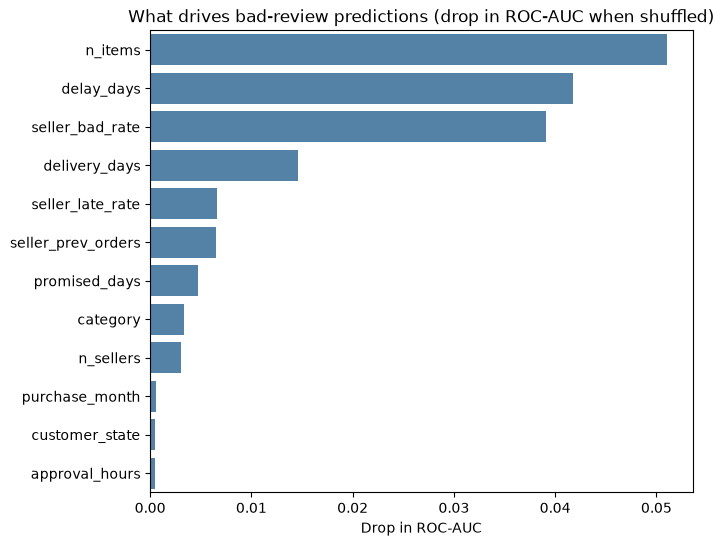

,feature,auc_drop
3,n_items,0.0510
1,delay_days,0.0418
13,seller_bad_rate,0.0391
0,delivery_days,0.0146
14,seller_late_rate,0.0066
12,seller_prev_orders,0.0065
10,promised_days,0.0047
16,category,0.0033
4,n_sellers,0.0030
17,purchase_month,0.0006


In [17]:
from sklearn.inspection import permutation_importance
import seaborn as sns

imp = permutation_importance(gb, X_test, y_test, scoring='roc_auc',
                             n_repeats=5, random_state=42)

importance = (pd.DataFrame({'feature': X_test.columns, 'auc_drop': imp.importances_mean})
              .sort_values('auc_drop', ascending=False))

plt.figure(figsize=(7, 6))
sns.barplot(data=importance.head(12), x='auc_drop', y='feature', color='steelblue')
plt.title('What drives bad-review predictions (drop in ROC-AUC when shuffled)')
plt.xlabel('Drop in ROC-AUC')
plt.ylabel('')
plt.savefig(FIG + r"\s3_feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()

importance.round(4)

**How to read ROC-AUC.** ROC = Receiver Operating Characteristic; AUC = Area Under the (ROC) Curve.
The model gives every order a risk score. AUC is the chance that a randomly chosen bad-review order gets a higher score than a randomly chosen good one.
0.5 = coin flip, 1.0 = perfect. Our final model scores 0.720: it ranks a bad-review order above a good one 72% of the time.

## Step 11. Checking the surprise: why does the number of items matter?
The model ranks n_items as the most important clue. Before treating that as a finding, check it directly in the data.

In [18]:
check = df.assign(items_group=pd.cut(df['n_items'], bins=[0, 1, 2, 3, 100],
                                     labels=['1', '2', '3', '4+']))

summary = check.groupby('items_group', observed=True).agg(
    orders=('bad_review', 'size'),
    bad_rate=('bad_review', 'mean'),
    late_rate=('is_late', 'mean'),
    multi_seller=('n_sellers', lambda s: (s > 1).mean()),
)
summary[['bad_rate', 'late_rate', 'multi_seller']] *= 100
summary.round(1)

,orders,bad_rate,late_rate,multi_seller
items_group,,,,
1,86301,11.3,6.8,0.0
2,7320,25.4,5.2,12.9
3,1286,29.1,4.8,15.6
4+,923,34.1,5.0,12.4


**Result:** bad reviews rise with the number of items: 11.3% (1 item), 25.4% (2), 29.1% (3), 34.1% (4+).
Lateness does not explain it: multi-item orders are late less often (about 5% vs 6.8%).
Multiple sellers explain only a small part: just 12 to 16% of multi-item orders involve more than one seller.
Next: check single-seller multi-item orders and read what customers wrote.

## Step 12. What do customers complain about on multi-item orders?
1. Keep only single-seller orders to remove the "separate parcels from different sellers" effect.
2. Search the review comments for Portuguese words that mean a missing or incomplete order.

In [19]:
# 1. Single-seller orders only
single = check[check['n_sellers'] == 1]
print(single.groupby('items_group', observed=True)['bad_review'].mean().mul(100).round(1))

# 2. Bring in the review comments
reviews = pd.read_parquet(r"..\data\processed\reviews_clean.parquet")
check2 = check.merge(reviews[['order_id', 'review_comment_message']], on='order_id', how='left')

missing_words = r'faltou|falta|faltando|só recebi|so recebi|apenas um|apenas 1|não recebi|nao recebi|incomplet'
check2['mentions_missing'] = (check2['review_comment_message']
                              .str.lower()
                              .str.contains(missing_words, regex=True, na=False))

bad = check2[check2['bad_review'] == 1]
print(bad.groupby('items_group', observed=True)['mentions_missing'].mean().mul(100).round(1))

items_group
1     11.3
2     22.4
3     25.7
4+    30.5
Name: bad_review, dtype: float64
items_group
1     14.4
2     38.1
3     37.4
4+    42.2
Name: mentions_missing, dtype: float64


**Finding: multi-item orders arrive incomplete.**
- Single-seller orders show the same pattern (22.4% bad reviews at 2 items vs 11.3% at 1 item), so separate sellers are not the cause.
- Among bad reviews, comments mentioning missing or undelivered items rise from 14.4% (1 item) to 37 to 42% (2+ items).
- Multi-item orders are about 10% of orders but produce roughly a fifth of bad reviews.

**Action:** packing check on 2+ item orders; tell the customer when items ship separately; send a "did everything arrive?" message at delivery so support can fix a missing item before the review is written.

**Caveats:** keyword matching is approximate; reviews without a comment count as "no mention", so the real share is likely higher. Stage 4 analyses the text properly.

## Step 13. Business case: what is the model worth in practice?
Support contacts the riskiest orders at delivery, before the review is written.
- Value is measured as bad reviews prevented, not money: Olist customers returned at the same rate after good and bad orders, so repeat sales cannot be claimed.
- The share of contacted customers that support can save is unknown, so three scenarios are shown (10%, 25%, 40%). These are assumptions, not results.
- Test period: about 3 months of orders (late May to end of August 2018).

In [21]:
import numpy as np
def business_case(proba, y_true, top_shares=(0.05, 0.10, 0.20),
                  save_rates=(0.10, 0.25, 0.40), months=3):
    """Contacts, bad reviews reached and prevented for each capacity and save-rate scenario."""
    y_true = np.asarray(y_true)
    order = np.argsort(proba)[::-1]          # riskiest orders first
    total_bad = y_true.sum()
    rows = []
    for share in top_shares:
        n = int(len(proba) * share)
        caught = y_true[order[:n]].sum()
        for rate in save_rates:
            prevented = caught * rate
            rows.append({
                'contact_top': f"{share:.0%}",
                'contacts_per_month': round(n / months),
                'bad_reached': int(caught),
                'save_rate': f"{rate:.0%}",
                'prevented': round(prevented),
                'pct_of_all_bad': round(prevented / total_bad * 100, 1),
                'contacts_per_prevented': round(n / prevented, 1),
            })
    return pd.DataFrame(rows)

proba_final = gb.predict_proba(X_test)[:, 1]
case = business_case(proba_final, y_test)
case

,contact_top,contacts_per_month,bad_reached,save_rate,prevented,pct_of_all_bad,contacts_per_prevented
0,5%,319,481,10%,48,2.6,19.9
1,5%,319,481,25%,120,6.5,8.0
2,5%,319,481,40%,192,10.4,5.0
3,10%,639,673,10%,67,3.6,28.5
4,10%,639,673,25%,168,9.1,11.4
5,10%,639,673,40%,269,14.5,7.1
6,20%,1278,918,10%,92,4.9,41.8
7,20%,1278,918,25%,230,12.4,16.7
8,20%,1278,918,40%,367,19.8,10.4


**Result.** The riskiest 5% of orders (about 319 a month, roughly 15 a working day) contain 481 of the test period's bad reviews: half of the contacted customers are genuinely at risk.
Going further gives diminishing returns: the next 5% of contacts hits only 20%, and the 10 to 20% band 13%, close to the 9.7% average.
Depending on how many contacted customers support can save (10 to 40%, assumed), this prevents 48 to 192 bad reviews per 3 months, at 5 to 20 contacts per prevented review.

**Recommendation:** personal support check-ins for the riskiest 5% of orders at delivery; extend to 10% only if capacity allows.
Save rates are assumptions; the first month should measure the real rate with a control group (as in stage 2).

### Tier 1: the multi-item rule
An automated "did everything arrive?" message to every order with 2+ items. How many bad reviews does it reach, and how much does it overlap with the model's top 5%?

In [22]:
y_arr = np.asarray(y_test)
multi = (X_test['n_items'] >= 2).values

n_top = int(len(proba_final) * 0.05)
top5 = np.zeros(len(proba_final), dtype=bool)
top5[np.argsort(proba_final)[::-1][:n_top]] = True

print("Tier 1 (2+ items): orders", multi.sum(),
      "| bad reviews", int(y_arr[multi].sum()),
      "| hit rate", round(y_arr[multi].mean() * 100, 1), "%")
print("Tier 2 (top 5%):   orders", top5.sum(),
      "| bad reviews", int(y_arr[top5].sum()))
print("In both tiers:     orders", (multi & top5).sum())
both = multi | top5
print("Either tier:       bad reviews", int(y_arr[both].sum()),
      "=", round(y_arr[both].sum() / y_arr.sum() * 100, 1), "% of all bad reviews")

Tier 1 (2+ items): orders 1816 | bad reviews 426 | hit rate 23.5 %
Tier 2 (top 5%):   orders 958 | bad reviews 481
In both tiers:     orders 467
Either tier:       bad reviews 708 = 38.2 % of all bad reviews


### Recommended plan: two tiers
| Tier | Who | How | Per month (approx.) |
| --- | --- | --- | --- |
| 1 | All orders with 2+ items not in tier 2 | Automated "did everything arrive?" message at delivery | 450 |
| 2 | Model's riskiest 5% of orders | Personal support check-in at delivery | 320 |

Together the tiers reach 708 of 1,853 bad reviews in the test period (38.2%) while contacting 12% of orders, versus 26% for the model alone.
The simple multi-item rule is 2.4 times better than random (23.5% vs 9.7%); the model adds the risky single-item orders a rule cannot see.
Measure the real effect in month one with a 10% control group per tier.

## Step 14. Ethics and limits

**What the model is for:** prioritising help. A flagged customer gets extra support; nobody is denied a service, a price or a delivery option because of a score.

**Rules for using it**
- Support fixes the problem; it never asks for a better review, asks for a review to be removed, or offers a reward for a positive one. Misrepresenting consumer reviews is a banned practice under the EU Unfair Commercial Practices Directive, as amended by Directive (EU) 2019/2161.
- Scoring customers is profiling under GDPR: the privacy notice should say that orders are scored to prioritise customer support.
- Customer state is in the model but adds almost nothing (importance 0.0005). It should be removed, so no region is treated differently.

**Limits**
- Brazilian marketplace data from 2016 to 2018. The method transfers; the numbers do not.
- The data drifted: bad reviews fell from 13.6% (training) to 9.7% (test) and late deliveries from 7.5% to 3.4%. The model should be retrained regularly.
- New sellers have no history, so the seller features cannot judge them yet.
- Delivery features are known only on arrival: the model scores orders at delivery, not at checkout.
- The save rates (10 to 40%) are assumptions, not measurements.
- Links in the data are not proof of cause. The multi-item finding is backed by review comments, but keyword matching is approximate.
- ROC-AUC 0.72: useful for ranking, far from certain. Half of the top 5% will not leave a bad review.

## Step 15. Predicting delivery time at checkout (regression)
Regression predicts a number instead of yes/no: here, days from purchase to delivery.
Only information known at checkout is used (no delivery dates, delays or approval time). Seller history is allowed because it comes from past orders.
Score: MAE (mean absolute error), the average number of days the prediction is off. Lower is better.
Benchmarks: Olist's own promised delivery time, and the median (same guess for every order).

In [24]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Only what is known at checkout
reg_numeric = ['n_items', 'n_sellers', 'total_price', 'total_freight', 'freight_share',
               'n_payments', 'max_installments', 'promised_days',
               'seller_prev_orders', 'seller_bad_rate', 'seller_late_rate']
reg_category = ['customer_state', 'category', 'purchase_month']

yr_train = X_train['delivery_days']
yr_test = X_test['delivery_days']

reg_prep = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), reg_numeric),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), reg_category),
])

reg_models = {
    'Linear regression': LinearRegression(),
    'Gradient boosting': HistGradientBoostingRegressor(random_state=42),
}

results = {
    'Olist promise': mean_absolute_error(yr_test, X_test['promised_days']),
    'Median (no skill)': mean_absolute_error(yr_test, np.full(len(yr_test), yr_train.median())),
}
reg_preds = {}
for name, model in reg_models.items():
    pipe = Pipeline([('prep', reg_prep), ('model', model)])
    pipe.fit(X_train, yr_train)
    reg_preds[name] = pipe.predict(X_test)
    results[name] = mean_absolute_error(yr_test, reg_preds[name])

print(pd.Series(results, name='MAE (days)').round(2))
print("\nHow early Olist's promise is, median days:",
      (X_test['promised_days'] - yr_test).median())

Olist promise        13.20
Median (no skill)     5.10
Linear regression     4.46
Gradient boosting     4.62
Name: MAE (days), dtype: float64

How early Olist's promise is, median days: 12.0


**Result.** Olist's promised date is not a forecast but a buffer: orders arrive a median 12 days early, so its error (13.2 days) is not a fair benchmark.
Against the no-skill median (5.10 days), linear regression improves only to 4.46 days (13%), and gradient boosting to 4.62.
With checkout information alone, delivery time is hard to predict. The missing clue is likely the distance between seller and customer.

In [25]:
for name, pred in reg_preds.items():
    print(name, "| average bias (predicted - actual):", round((pred - yr_test).mean(), 2), "days")
print("Median actual delivery days: train", yr_train.median(), "| test", yr_test.median())

Linear regression | average bias (predicted - actual): 2.51 days
Gradient boosting | average bias (predicted - actual): 2.93 days
Median actual delivery days: train 11.0 | test 7.0


In [26]:
import os
print(os.listdir(r"..\data\raw"))
print([c for c in X_test.columns if 'zip' in c or 'seller' in c])

['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'online_retail_ii', 'product_category_name_translation.csv']
['n_sellers', 'seller_prev_orders', 'seller_bad_rate', 'seller_late_rate']


**Drift check.** Median delivery fell from 11 days (training) to 7 days (test). Both models over-predict by 2.5 to 2.9 days on average; gradient boosting, which fits the training period more closely, by more. This explains why linear regression won, and shows why a delivery model must be retrained on recent data.

## Step 15b. Adding the missing clue: distance from seller to customer
Each zip prefix gets one map point (average latitude and longitude). Distance is the straight-line ("as the crow flies") distance in km between the seller of the first item and the customer, using the haversine formula for distances on a sphere. same_state flags whether both are in the same state.

In [27]:
RAW = r"..\data\raw"

geo = pd.read_csv(RAW + r"\olist_geolocation_dataset.csv")
zip_xy = geo.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].mean()

orders_raw = pd.read_csv(RAW + r"\olist_orders_dataset.csv", usecols=['order_id', 'customer_id'])
customers = pd.read_csv(RAW + r"\olist_customers_dataset.csv",
                        usecols=['customer_id', 'customer_zip_code_prefix', 'customer_state'])
items = pd.read_csv(RAW + r"\olist_order_items_dataset.csv", usecols=['order_id', 'order_item_id', 'seller_id'])
sellers = pd.read_csv(RAW + r"\olist_sellers_dataset.csv",
                      usecols=['seller_id', 'seller_zip_code_prefix', 'seller_state'])

first_seller = items[items['order_item_id'] == 1][['order_id', 'seller_id']]

route = (orders_raw
         .merge(customers, on='customer_id', how='left')
         .merge(first_seller, on='order_id', how='left')
         .merge(sellers, on='seller_id', how='left')
         .merge(zip_xy, left_on='customer_zip_code_prefix', right_index=True, how='left')
         .merge(zip_xy, left_on='seller_zip_code_prefix', right_index=True, how='left',
                suffixes=('_cust', '_sell')))

def haversine_km(lat1, lng1, lat2, lng2):
    """Straight-line distance in km between two map points."""
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

route['distance_km'] = haversine_km(route['geolocation_lat_cust'], route['geolocation_lng_cust'],
                                    route['geolocation_lat_sell'], route['geolocation_lng_sell'])
route['same_state'] = (route['customer_state'] == route['seller_state']).astype(int)

route = route.set_index('order_id')
print("Orders with a distance:", route['distance_km'].notna().mean().round(3))
print("Median distance (km):", route['distance_km'].median().round(0))

Orders with a distance: 0.987
Median distance (km): 434.0


In [28]:
assert X_train.index.isin(df.index).all()   # safety check: rows still line up with df

for X in (X_train, X_test):
    ids = df.loc[X.index, 'order_id']
    X['distance_km'] = ids.map(route['distance_km']).values
    X['same_state'] = ids.map(route['same_state']).values

reg_numeric2 = reg_numeric + ['distance_km', 'same_state']
reg_prep2 = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), reg_numeric2),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), reg_category),
])

for name, model in reg_models.items():
    pipe = Pipeline([('prep', reg_prep2), ('model', model)])
    pipe.fit(X_train, yr_train)
    pred = pipe.predict(X_test)
    reg_preds[name + ' + distance'] = pred
    print(f"{name} + distance | MAE {mean_absolute_error(yr_test, pred):.2f} days"
          f" | bias {(pred - yr_test).mean():.2f} days")

Linear regression + distance | MAE 4.45 days | bias 2.59 days
Gradient boosting + distance | MAE 4.79 days | bias 3.28 days


**Result.** Adding seller-to-customer distance (median 434 km, available for 98.7% of orders) did not improve the model: linear regression 4.46 → 4.45 days; gradient boosting got worse (4.62 → 4.79).
The likely reason is that the information was already there: Olist's promised delivery time and the customer's state already reflect the route.
Most of the remaining error is drift: the models over-predict by about 2.6 days because deliveries got faster.

## Step 15c. Is distance already in the promise? And does training on recent data fix the drift?
1. Correlation between promised days and distance.
2. Retrain linear regression on only the most recent 3, 6 and 12 months of the training period.

In [29]:
# 1. Is distance already inside the promise?
print(X_train[['promised_days', 'distance_km']].corr().round(2), "\n")

# 2. Train on recent months only
dates = df.loc[X_train.index, 'order_purchase_timestamp']
for months in (3, 6, 12):
    recent = dates >= dates.max() - pd.DateOffset(months=months)
    pipe = Pipeline([('prep', reg_prep2), ('model', LinearRegression())])
    pipe.fit(X_train[recent], yr_train[recent])
    pred = pipe.predict(X_test)
    print(f"Last {months} months ({recent.sum():,} orders) | "
          f"MAE {mean_absolute_error(yr_test, pred):.2f} days | bias {(pred - yr_test).mean():.2f} days")

               promised_days  distance_km
promised_days           1.00         0.54
distance_km             0.54         1.00 

Last 3 months (20,306 orders) | MAE 6.18 days | bias 5.08 days
Last 6 months (39,998 orders) | MAE 6.04 days | bias 4.89 days
Last 12 months (66,203 orders) | MAE 4.42 days | bias 2.37 days


**Result.** Promised days and distance correlate at 0.54, so the promise already carries much of the route information.
Training on only the last 3 or 6 months made predictions worse (MAE about 6 days, over-predicting by about 5); the last 12 months gave the best result (MAE 4.42, bias 2.37).

**Why:** the monthly check shows the slow patches were November 2017 (Black Friday peak, 12.3% late) and February to March 2018 (13 to 14 days median, up to 18.7% late). The last 3 and 6 months of training are centred on those slow months; the test period (June to August, 7 days median) was the fastest. The data does not show why February and March were slow.

**Lesson:** "most recent" data is not automatically "most representative". A delivery model needs monthly error monitoring and recalibration.

**Final delivery model:** linear regression trained on the last 12 months (MAE 4.42 days).

In [30]:
monthly = (df.assign(month=df['order_purchase_timestamp'].dt.to_period('M'))
             .groupby('month')
             .agg(orders=('delivery_days', 'size'),
                  median_days=('delivery_days', 'median'),
                  late_pct=('is_late', 'mean')))
monthly['late_pct'] *= 100
monthly.loc['2017-10':'2018-08'].round(1)

,orders,median_days,late_pct
month,,,
2017-10,4446,10.0,4.0
2017-11,7237,12.0,12.3
2017-12,5461,13.0,7.3
2018-01,7013,11.0,5.6
2018-02,6508,14.0,14.0
2018-03,6948,13.0,18.7
2018-04,6752,9.0,4.4
2018-05,6722,9.0,6.5
2018-06,6072,7.0,1.2


## Step 16. Removing customer state
Customer state added almost nothing (importance 0.0005), and using location risks treating regions differently. Retrain the final model with the state blanked out and check that performance holds.

In [31]:
from sklearn.base import clone

gb_ns = clone(gb)
gb_ns.fit(X_train.assign(customer_state='removed'), y_train)
proba_ns = gb_ns.predict_proba(X_test.assign(customer_state='removed'))[:, 1]
evaluate('Gradient boosting + seller history, no state', proba_ns)

{'model': 'Gradient boosting + seller history, no state',
 'roc_auc': 0.717,
 'capture_top5': np.float64(25.7),
 'precision_top5': np.float64(49.8),
 'capture_top10': np.float64(36.4),
 'precision_top10': np.float64(35.3),
 'capture_top20': np.float64(48.9),
 'precision_top20': np.float64(23.7)}

**Result.** Without customer state: ROC-AUC 0.717 (was 0.720), top 5% precision 49.8% (was 50.2%). The difference is negligible, so the final model excludes customer state and no region is treated differently.